<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_FederatedIoMT_Baihan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN federated learning for IoMT threat detection: Baihan et al. (QLFL) step by step

**Paper.** A. Baihan, A. Irshad, M. Amoon, W. Jiang, A. T. Tegene and Z. Ullah, *QLFL: quantum-enabled lightweight
federated learning-empowered threat detection model for Internet of Medical Things based healthcare*,
**Scientific Reports** (2026, article in press), doi [10.1038/s41598-026-75352-z](https://doi.org/10.1038/s41598-026-75352-z).

**What this notebook does.** It rebuilds the QLFL pipeline of the paper from scratch and runs it end to end on the public
*IoT Healthcare Security dataset* (Hussain et al., Sensors 2021): a 5-qubit variational quantum circuit followed by a
bidirectional GRU, trained by several simulated clients with **asynchronous federated averaging (FedAsync)**, a
**knowledge-distilled lightweight student** kept on each client, and **additively homomorphic encryption (Paillier,
written in pure Python here)** of the model parameters during aggregation. Every step is explained in plain language, the
quantum layer is simulated exactly and checked against a PennyLane circuit, the encrypted aggregation is checked against the
plaintext average, a classical twin of the whole pipeline and a federated random forest are trained on exactly the same
inputs, and the notebook ends with an honest claim-by-claim comparison with the paper's numbers.

**How to run.** Open in Google Colab, choose a **CPU** runtime and press *Runtime, Run all*. With `FAST_MODE = True` it
finishes in a few minutes (small client sets, 4 federated rounds); `FAST_MODE = False` follows the paper's 10 federated
rounds on the whole training split with several seeds (about 40 minutes on a shared 8-core CPU). No GPU, no API key and no account are
needed: the data come from a public GitHub repository.

**What you get at the end.** Real-data exploration plots, the drawn circuits that are actually executed, per-client
loss/accuracy curves, confusion matrices and ROC curves for 5 and 10 clients, the cost of encryption, and a table that says,
for each claim of the paper, *reproduced*, *not reached*, *exceeded* or *cannot be checked*.

## The paper in one page

**Problem.** Medical devices (IoMT) produce network traffic that must be screened for attacks, but raw traffic cannot be
centralised (privacy) and the devices are weak (cost). The paper asks for an intrusion detector that is accurate, trained
without sharing data, small enough for a device, and whose model updates are confidential.

**Decision.** Binary: benign traffic (0) versus attack (1) for every network record (a captured MQTT/TCP packet).

**Method (QLFL).**
1. *Hybrid model.* A trainable linear projection maps the 51 normalised features to 5 angles, `z = pi * tanh(W x + b)` (Eq. 24).
   Each angle is written into one qubit with an `RY` rotation (Eq. 25). Two variational layers of `RX, RY, RZ` rotations and
   `CNOT` entanglers follow (Eq. 26); the Pauli-Z expectation of each qubit is measured (Eq. 27). The five numbers go into a
   BiLSTM/BiGRU and a sigmoid dense layer, trained end to end with binary cross-entropy and Adam; gradients of the circuit
   use the parameter-shift rule (Eq. 7, 14).
2. *Federated training.* Clients train locally, send parameters (never data). The server mixes each arriving update into
   the global model with a staleness-aware weight, `alpha_i = alpha_0 (1 + s_i)^(-beta)`, updates older than `S_max` are
   dropped, `theta_g <- (1 - alpha_i) theta_g + alpha_i theta_i` (Eq. 18-20), so it never waits for slow clients (FedAsync).
3. *Knowledge distillation.* A larger teacher QNN is distilled into a compact student that stays on the device; only the
   teacher's update is exchanged (Algorithm 1).
4. *Encryption.* Model parameters are encrypted before upload and the mixing of Eq. (20) is done on ciphertexts; only the
   aggregate is decrypted (Eq. 21). The abstract says *additive homomorphic encryption*, the experimental section says CKKS
   (PySEAL, N, {60,40,40,60}-bit chain, Table 7). This notebook uses Paillier, which is additive (see the table below).

**Data.** *IoT Healthcare Security dataset* (Table 5): 112,659 + 56,137 training and 48,384 + 23,989 test records
(benign + attack), stratified 70/30 split before any preprocessing, min-max scaling fitted on the training part, clients
receive IID stratified shares; 5 and 10 clients, 10 federated rounds, 200 local epochs per round.

**Claims to check.** Accuracy 98.90 % (abstract and conclusion) and 98.37 % (Fig. 3, Table 9); for "Client 1" precision
99.40 %, recall 99.01 %, F1 99.20 % (Fig. 3); maximum ROC-AUC 0.9990 (Fig. 7); per-class results for benign, publish flood,
authentication bypass, packet crafting and replay attack (Table 6); the same level with 10 clients as with 5 (Fig. 4-7);
student 45.6 % smaller, 47 ms detection latency, 40 % faster rounds (Table 8); CKKS overhead (Table 7); encrypted
aggregation does not harm accuracy.

### What follows the paper and what had to be chosen

The paper gives the model family but omits many numbers (and Algorithms 1 and 2 are figures without text). Every row marked
*chosen* is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | IoT Healthcare Security (Hussain et al. 2021), 51 predictors, "binary" target, Table 5 counts | Same dataset from the authors' public GitHub repository (3 CSV files, 188,694 records, 50 columns + label). Attack count matches Table 5 exactly (80,126); the public benign files hold 108,568 records, not the 161,043 of Table 5 |
| Features | 51 predictors | identifier / timestamp / free-text columns dropped (IPs, ports, payload, client id, topic, message, checksum, relative time, class), constants dropped on the training split: about 30 features (chosen, see section 1) |
| Split | stratified 70/30, fixed seed | stratified 70/30, `SEED = 42` (same) |
| Scaling | min-max fitted on train | same |
| Qubits, encoding | 5, `RY(z_j)` angle embedding of `z = pi tanh(Wx+b)` | same |
| Variational layers | 2 layers of `RX, RY, RZ` + CNOT | same; CNOT ring `0-1-2-3-4-0` and uniform [0, 2 pi) initial angles (chosen) |
| Classical head | BiLSTM or BiGRU + dense sigmoid | BiGRU, hidden 8 per direction, reads the 5 expectation values as a sequence of length 5 (chosen) |
| Teacher / student | "larger QNN" and "lightweight student", sizes not given | teacher: 2-layer VQC + BiGRU(8); student: 1-layer VQC + BiGRU(4) (chosen); loss `lambda*BCE + (1-lambda) T^2 KL`, `T = 2`, `lambda = 0.5` (chosen) |
| Optimiser | Adam, learning rate not given | Adam, `lr = 0.01`, batch 512, fresh optimiser state each local round (chosen) |
| Gradients | parameter-shift | exact autograd of the exact simulator; equality with the parameter-shift rule is asserted (section 3) |
| Quantum backend | PennyLane `default.qubit`, Qiskit Aer, TFQ | exact batched state-vector simulator in PyTorch, asserted equal to a PennyLane QNode (section 3) |
| Local epochs / rounds | 200 epochs per round, 10 rounds | `FAST_MODE`: 1 + 1 epoch, 3 rounds; full: 2 teacher + 1 student epochs, 10 rounds (the 200-epoch budget is not feasible on a CPU simulator) |
| Clients | 5 and 10, IID stratified | same |
| FedAsync | `alpha_0`, `beta`, `S_max` not given | `alpha_0 = 0.6`, `beta = 0.5`, `S_max = 12`; heterogeneous simulated client speeds decide the arrival order (chosen) |
| Encryption | CKKS (PySEAL), N, 128-bit security | Paillier (additive), 1024-bit modulus for speed (2048 recommended), parameters packed in 64-bit slots, 24-bit fixed point (chosen; CKKS needs a library that is not installed) |
| Seeds | one fixed run | `FAST_MODE`: one seed; full: three seeds (mean +- std) |
| Baselines | other published methods (Table 9) | a classical twin of the same federated pipeline (5-to-5 tanh layer instead of the circuit), a federated random forest and a centralised random forest, all on the same inputs |

In [1]:
# 0. Installs (pinned to the versions this notebook was tested with). Colab already ships numpy, pandas,
#    scikit-learn, matplotlib and PyTorch. PennyLane is used to draw the circuits and to check the simulator.
#    The cell does nothing locally when PennyLane is already installed. A session restart is normally not needed.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules

def _missing(mod):
    try:
        importlib.import_module(mod)
        return False
    except Exception:
        return True

if IN_COLAB or _missing("pennylane"):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
if _missing("torch"):
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "torch"])

In [2]:
# 1. Configuration: every tunable constant lives here.
FAST_MODE = False          # True: a few minutes (class demo). False: the paper's 10 rounds on the whole training split.
SEED = 42
N_QUBITS = 5                    # fixed by the paper (five-qubit circuit)
TEST_SIZE = 0.3                 # paper: stratified 70/30
DATA_DIR = "iomt_data"          # cache folder (downloaded zip + extracted CSV, large CSVs are deleted after use)
LOCAL_ZIP = ""                  # optional: path to your own copy of ICUDatasetProcessed.zip
ZIP_URLS = [
    "https://raw.githubusercontent.com/imfaisalmalik/IoT-Healthcare-Security-Dataset/main/Dataset/ICUDatasetProcessed.zip",
    "https://github.com/imfaisalmalik/IoT-Healthcare-Security-Dataset/raw/main/Dataset/ICUDatasetProcessed.zip",
]
IBM_TOKEN = ""                  # not used: the circuit runs on an exact simulator (no real-hardware cell in this paper)

# --- federated protocol -----------------------------------------------------------------------------------------
K_CLIENTS, K_CLIENTS_LARGE = 5, 10          # the two client counts of the paper (Fig. 4-7)
if FAST_MODE:
    MAX_TRAIN = 24000                       # training rows kept (stratified sample of the 70 % training split)
    ROUNDS, ROUNDS_LARGE = 4, 2             # one round = one accepted update from every client
    E_TEACHER, E_STUDENT = 1, 1             # local epochs per round (paper: 200)
    SEEDS = [SEED]
else:
    MAX_TRAIN = None                        # whole training split (about 132 000 rows)
    ROUNDS, ROUNDS_LARGE = 10, 10           # paper: 10 federated rounds
    E_TEACHER, E_STUDENT = 2, 1
    SEEDS = [SEED, SEED + 1, SEED + 2]      # different initialisations / client shares; the data split stays fixed
BATCH, LR = 512, 0.01                       # CHOICE: not given in the paper
L_T, HID_T = 2, 8                           # teacher: variational layers, GRU hidden size per direction
L_S, HID_S = 1, 4                           # student (lightweight)
KD_T, KD_LAMBDA = 2.0, 0.5                  # CHOICE: distillation temperature and hard/soft balance
ALPHA0, BETA, S_MAX = 0.6, 0.5, 12          # CHOICE: FedAsync base mixing weight, staleness decay, staleness cut-off
HE_KEY_BITS, HE_FRAC_BITS, HE_WEIGHT_BITS = 1024, 24, 16   # CHOICE: Paillier modulus, fixed-point bits, weight resolution
N_PLOT = 4000                               # real records drawn in the scatter plots
PAPER = dict(acc_abstract=98.90, acc_fig3=98.37, prec=99.40, rec=99.01, f1=99.20, auc=0.9990)   # numbers quoted from the paper
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| rounds:", ROUNDS, ROUNDS_LARGE, "| local epochs (teacher, student):", E_TEACHER, E_STUDENT)

FAST_MODE = False | seeds: [42, 43, 44] | rounds: 10 10 | local epochs (teacher, student): 2 1


In [3]:
# 2. Imports, seeds, versions.
import os, io, math, time, random, zipfile, pathlib, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve)
import heapq
warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(1)                      # one thread: reproducible and friendly to shared machines
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
for name, mod in [("python", sys), ("numpy", np), ("pandas", pd), ("torch", torch), ("pennylane", qml), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{name:13s}", getattr(mod, "__version__", sys.version.split()[0]))

python        3.12.10
numpy         2.5.4
pandas        3.0.6
torch         2.14.1+cpu
pennylane     0.45.1
scikit-learn  1.9.1
matplotlib    3.11.2


## 1. Data, labels and the 70/30 split

The paper says only "IoT Healthcare Security dataset" and cites Hussain et al. (Sensors 2021). That dataset simulates an
intensive-care unit with two beds (nine patient-monitoring sensors and one control unit per bed) built with the *IoT-Flock*
generator. It is published on IEEE DataPort (subscription needed) and by the authors on **GitHub and Kaggle**. The GitHub copy
(`ICUDatasetProcessed.zip`, 16 MB) is downloadable without an account and is what this notebook uses. It has three CSV files,
one packet per row with 50 Wireshark-style columns (`frame.*`, `ip.*`, `tcp.*`, `mqtt.*`) plus a `class` column
(`patientMonitoring`, `environmentMonitoring`, `Attack`) and a binary `label` (0 benign, 1 attack).

**Honest note on the counts.** The attack file has 80,126 rows, exactly the sum of the attack rows in the paper's Table 5
(56,137 + 23,989). The two benign files have 31,758 + 76,810 = 108,568 rows, whereas Table 5 lists 112,659 + 48,384 = 161,043
benign rows. The public data therefore contain 52,475 fewer benign records than the paper used, and the public files have no
attack sub-types (the paper's Table 6 reports publish flood, authentication bypass, packet crafting and replay attack).

In [4]:
# 3a. Download (or read the local copy), extract, load. Large CSVs are deleted afterwards (the zip stays as the cache).
DATA_DIR = pathlib.Path(DATA_DIR); DATA_DIR.mkdir(parents=True, exist_ok=True)
zip_path = pathlib.Path(LOCAL_ZIP) if LOCAL_ZIP else DATA_DIR / "ICUDatasetProcessed.zip"
if not zip_path.exists():
    for url in ZIP_URLS:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            zip_path.write_bytes(r.content); print("downloaded", url, f"({len(r.content)/1e6:.1f} MB)"); break
        except Exception as e:
            print("failed:", url, type(e).__name__)
    else:
        raise RuntimeError("Could not download the dataset. Put ICUDatasetProcessed.zip next to the notebook and set LOCAL_ZIP.")
ext = DATA_DIR / "extracted"
with zipfile.ZipFile(zip_path) as z:
    z.extractall(ext)
csvs = sorted(ext.rglob("*.csv"))
frames = []
for f in csvs:
    d = pd.read_csv(f, low_memory=False); d["source_file"] = f.stem; frames.append(d)
    print(f"{f.name:28s} rows={len(d):7d} cols={d.shape[1]-1}")
raw = pd.concat(frames, ignore_index=True)
for f in csvs:                                   # keep the cache small: delete extracted files above 50 MB
    if f.stat().st_size > 50e6:
        f.unlink()
print("combined:", raw.shape)

Attack.csv                   rows=  80126 cols=52


environmentMonitoring.csv    rows=  31758 cols=52


patientMonitoring.csv        rows=  76810 cols=52
combined: (188694, 53)


In [5]:
# 3b. Cleaning and labels. Free-text / identifier columns are dropped, hexadecimal fields are converted to numbers.
# CHOICE: the paper uses "51 predictors" without listing them. IP addresses, ports, payload, client id, topic, message,
# checksum and the relative time stamp identify the capture session (the attack traffic was recorded in another subnet,
# see the table below) and would let any model "detect" the capture, not the attack, so they are excluded.
ID_COLS = ["ip.src", "ip.dst", "tcp.srcport", "tcp.dstport", "tcp.payload", "mqtt.clientid", "mqtt.msg", "mqtt.topic",
           "tcp.checksum", "frame.time_relative", "class", "label", "source_file"]

def to_number(x):
    if isinstance(x, str) and x.startswith("0x"):
        return float(int(x, 16))
    return pd.to_numeric(x, errors="coerce")

feat = raw.drop(columns=ID_COLS)
for c in feat.columns:
    if not pd.api.types.is_numeric_dtype(feat[c]):
        feat[c] = feat[c].map(to_number)
feat = feat.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
n_bad = int(feat.isna().any(axis=1).sum())
feat = feat.fillna(0.0)                          # CHOICE: the data authors' own code also fills missing fields with 0
y_all = raw["label"].astype(int).to_numpy()
cls_all = raw["class"].astype(str).to_numpy()
print("rows with missing/inf values filled with 0:", n_bad)
print("feature matrix:", feat.shape, "| labels:", dict(zip(*np.unique(y_all, return_counts=True))))
subnet = raw["ip.src"].astype(str).str.extract(r"^(\d+\.\d+)")[0].fillna("none")
print("\nsource-address prefix (ip.src, first two bytes) per original class, why identifiers are dropped:")
print(pd.crosstab(subnet, raw["class"]).to_string())

rows with missing/inf values filled with 0: 0
feature matrix: (188694, 40) | labels: {np.int64(0): np.int64(108568), np.int64(1): np.int64(80126)}



source-address prefix (ip.src, first two bytes) per original class, why identifiers are dropped:
class    Attack  environmentMonitoring  patientMonitoring
0                                                        
10.16      9202                      0                  0
10.5          0                  31758              76810
192.168   70924                      0                  0


In [6]:
# 3c. Stratified 70/30 split BEFORE any fitted preprocessing (paper), then scaling fitted on the training part only.
idx_all = np.arange(len(feat))
tr_idx, te_idx = train_test_split(idx_all, test_size=TEST_SIZE, stratify=cls_all, random_state=SEED)
if MAX_TRAIN is not None and MAX_TRAIN < len(tr_idx):                 # FAST_MODE: stratified sample of the training split
    tr_idx, _ = train_test_split(tr_idx, train_size=MAX_TRAIN, stratify=cls_all[tr_idx], random_state=SEED)
Xtr_df, Xte_df = feat.iloc[tr_idx], feat.iloc[te_idx]
const_cols = [c for c in feat.columns if Xtr_df[c].nunique() == 1]    # decided on the training split only
FEATURES = [c for c in feat.columns if c not in const_cols]
scaler = MinMaxScaler().fit(Xtr_df[FEATURES])                         # Eq. 22, fitted on train only
Xtr = scaler.transform(Xtr_df[FEATURES]).astype(np.float32)
Xte = scaler.transform(Xte_df[FEATURES]).astype(np.float32)          # Eq. 23, same parameters; not clipped (as in the paper)
ytr, yte = y_all[tr_idx], y_all[te_idx]
ctr, cte = cls_all[tr_idx], cls_all[te_idx]
D = Xtr.shape[1]
print(f"constant columns dropped on the training split ({len(const_cols)}):", const_cols)
print(f"model input dimension D = {D} (paper: 51)")
print(f"train {Xtr.shape} (benign {int((ytr==0).sum())}, attack {int((ytr==1).sum())})   test {Xte.shape} (benign {int((yte==0).sum())}, attack {int((yte==1).sum())})")
print("paper Table 5: train benign 112,659 / attack 56,137, test benign 48,384 / attack 23,989")

constant columns dropped on the training split (10): ['tcp.flags.urg', 'mqtt.conack.flags', 'mqtt.conack.val', 'mqtt.conflag.passwd', 'mqtt.conflag.qos', 'mqtt.conflag.reserved', 'mqtt.conflag.retain', 'mqtt.conflag.willflag', 'mqtt.willmsg_len', 'ip.proto']
model input dimension D = 30 (paper: 51)
train (132085, 30) (benign 75997, attack 56088)   test (56609, 30) (benign 32571, attack 24038)
paper Table 5: train benign 112,659 / attack 56,137, test benign 48,384 / attack 23,989


## 2. Dataset Exploration and Visualisation

Everything below is drawn from the real records only: nothing is simulated or invented. We print the shape, the original
column names and label values, plot the real class distribution, and place real training records in a 2-D map coloured by their
ground-truth class. Because the paper encodes features as rotation angles, the second map shows the same kind of
projection scaled to angles in `[0, pi]`. The decision is binary, but the files keep three real traffic types, so the colouring
keeps them (attack, patient monitoring, environment monitoring).

In [7]:
# 4a. Shapes, names, label values and counts (real data).
print("raw table (all three CSV files):", raw.drop(columns="source_file").shape)
print("\noriginal columns (", raw.shape[1] - 1, "):")
print([c for c in raw.columns if c != "source_file"])
print("\nlabel values:", sorted(raw['label'].unique().tolist()), "-> 0 = benign, 1 = attack")
print("class values :", sorted(raw['class'].unique().tolist()))
print(pd.crosstab(raw['class'], raw['label']).to_string())
print(f"\nmodel features used ({D}):", FEATURES)

raw table (all three CSV files): (188694, 52)

original columns ( 52 ):
['frame.time_delta', 'frame.time_relative', 'frame.len', 'ip.src', 'ip.dst', 'tcp.srcport', 'tcp.dstport', 'tcp.flags', 'tcp.time_delta', 'tcp.len', 'tcp.ack', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.sack', 'tcp.connection.syn', 'tcp.flags.ack', 'tcp.flags.fin', 'tcp.flags.push', 'tcp.flags.reset', 'tcp.flags.syn', 'tcp.flags.urg', 'tcp.hdr_len', 'tcp.payload', 'tcp.pdu.size', 'tcp.window_size_value', 'tcp.checksum', 'mqtt.clientid', 'mqtt.clientid_len', 'mqtt.conack.flags', 'mqtt.conack.val', 'mqtt.conflag.passwd', 'mqtt.conflag.qos', 'mqtt.conflag.reserved', 'mqtt.conflag.retain', 'mqtt.conflag.willflag', 'mqtt.conflags', 'mqtt.dupflag', 'mqtt.hdrflags', 'mqtt.kalive', 'mqtt.len', 'mqtt.msg', 'mqtt.msgtype', 'mqtt.qos', 'mqtt.retain', 'mqtt.topic', 'mqtt.topic_len', 'mqtt.ver', 'mqtt.willmsg_len', 'ip.proto', 'ip.ttl', 'class', 'label']

label values: [0, 1] -> 0 = benign, 1 = attack
class val

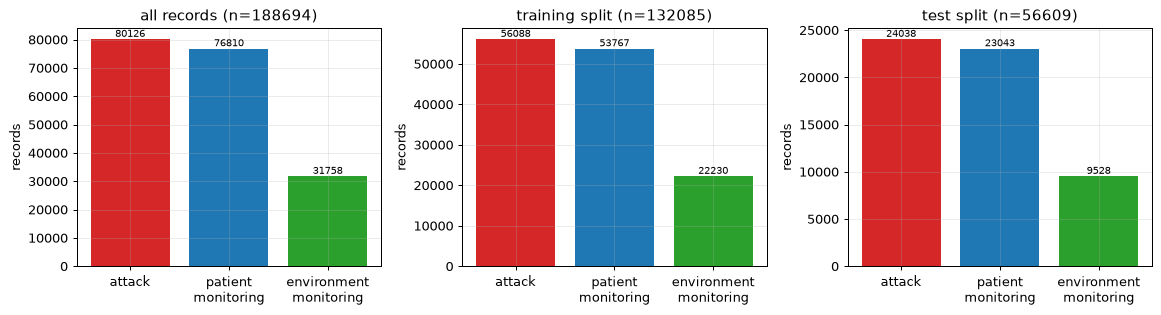

In [8]:
# 4b. Real class distribution: whole dataset, train and test splits.
CLASS_ORDER = ["Attack", "patientMonitoring", "environmentMonitoring"]
CLASS_COL = {"Attack": "#d62728", "patientMonitoring": "#1f77b4", "environmentMonitoring": "#2ca02c"}
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (title, cs) in zip(ax, [("all records", cls_all), ("training split", ctr), ("test split", cte)]):
    vals = [int((cs == c).sum()) for c in CLASS_ORDER]
    bars = a.bar(range(3), vals, color=[CLASS_COL[c] for c in CLASS_ORDER])
    a.set_xticks(range(3)); a.set_xticklabels(["attack", "patient\nmonitoring", "environment\nmonitoring"])
    a.set_title(f"{title} (n={len(cs)})"); a.set_ylabel("records")
    for b, v in zip(bars, vals):
        a.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

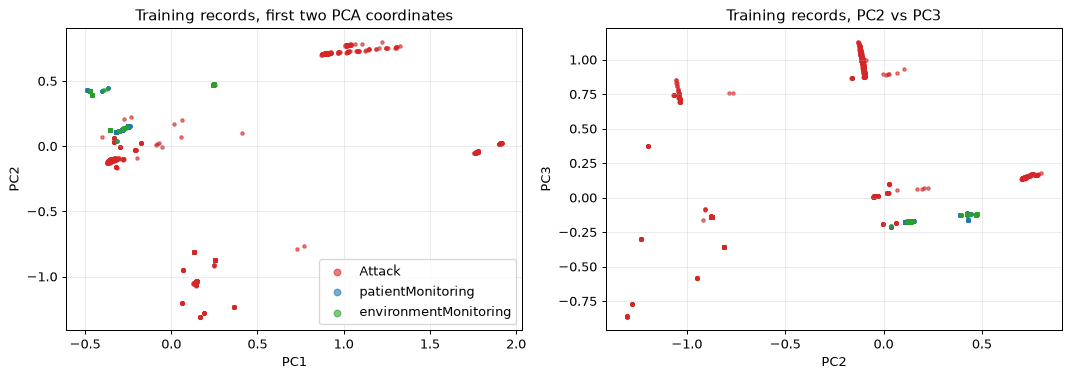

explained variance of the first five components: [0.331 0.223 0.148 0.061 0.051]


In [9]:
# 4c. 2-D map of real training records coloured by ground-truth class: raw PCA coordinates (fitted on the training split)
rs = np.random.default_rng(SEED)
pick = rs.choice(len(Xtr), size=min(N_PLOT, len(Xtr)), replace=False)
pca5 = PCA(n_components=N_QUBITS, random_state=SEED).fit(Xtr)             # fitted on the training split only
P = pca5.transform(Xtr)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for c in CLASS_ORDER:
    m = ctr[pick] == c
    ax[0].scatter(P[pick][m, 0], P[pick][m, 1], s=7, alpha=0.6, c=CLASS_COL[c], label=c)
    ax[1].scatter(P[pick][m, 1], P[pick][m, 2], s=7, alpha=0.6, c=CLASS_COL[c], label=c)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].set_title("Training records, first two PCA coordinates")
ax[1].set_xlabel("PC2"); ax[1].set_ylabel("PC3"); ax[1].set_title("Training records, PC2 vs PC3")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("explained variance of the first five components:", np.round(pca5.explained_variance_ratio_, 3))

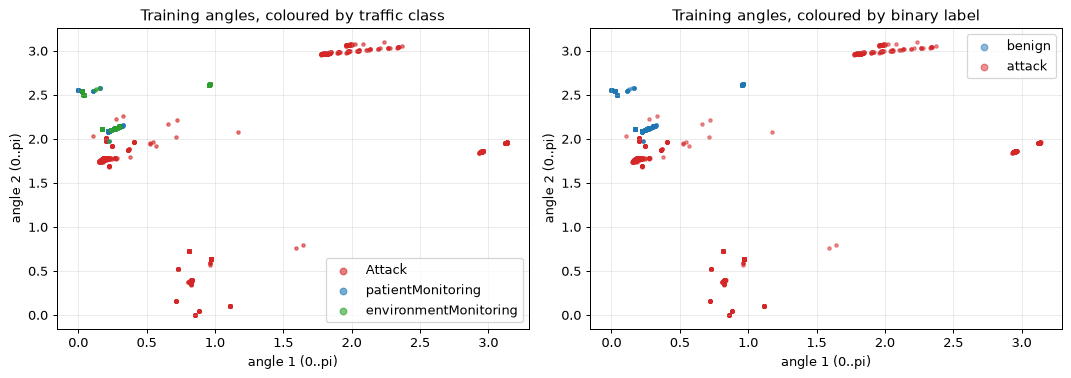

In [10]:
# 4d. The same coordinates scaled to [0, pi] (angle encoding as in the reference notebooks). The QLFL model itself uses a
# learned projection z = pi*tanh(Wx+b) instead of PCA; those learned angles are drawn after training (section 7).
ang_scaler = MinMaxScaler((0, np.pi)).fit(P)                               # fitted on training PCA coordinates
A = ang_scaler.transform(P)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for c in CLASS_ORDER:
    m = ctr[pick] == c
    ax[0].scatter(A[pick][m, 0], A[pick][m, 1], s=7, alpha=0.6, c=CLASS_COL[c], label=c)
for lab, col, nm in [(0, "#1f77b4", "benign"), (1, "#d62728", "attack")]:
    m = ytr[pick] == lab
    ax[1].scatter(A[pick][m, 0], A[pick][m, 1], s=7, alpha=0.5, c=col, label=nm)
for a, t in zip(ax, ["Training angles, coloured by traffic class", "Training angles, coloured by binary label"]):
    a.set_xlabel("angle 1 (0..pi)"); a.set_ylabel("angle 2 (0..pi)"); a.set_title(t); a.legend(markerscale=2)
plt.tight_layout(); plt.show()

## 3. Quantum Circuit Architecture

The paper's circuit has five qubits. Each learned angle `z_j` is written with `RY(z_j)` on qubit `j` (Eq. 25). Each variational
layer applies `RX`, `RY`, `RZ` with trainable angles on every qubit (Eq. 26) and then `CNOT` gates; the Pauli-Z expectation of
every qubit is measured (Eq. 27). The paper does not say which qubit pairs are entangled; we use a ring
(0-1, 1-2, 2-3, 3-4, 4-0) and uniform random initial angles (`# CHOICE`).

For speed the training code does not call PennyLane for every record. It uses an exact batched state-vector simulation
written in PyTorch (the trainable part is one 32x32 unitary shared by all records). **This simulator is asserted to give the same
numbers as the PennyLane QNode below, and its autograd gradients are asserted to equal the parameter-shift rule** of
Eq. 7 and 14. The drawings are those of the PennyLane QNode that is executed in the equivalence test. Two architectures are
used: the teacher (2 variational layers) and the student (1 layer).

In [11]:
# 4. Exact simulator of the paper's circuit (Eq. 25-27) and the parameter-shift rule (Eq. 7, 14).

NQ = N_QUBITS
_CDT = torch.complex128


def _rot_mats(theta):
    """theta (..., 3) -> fused single-qubit unitary RZ(t3) RY(t2) RX(t1)  (RX is applied first)  shape (...,2,2)."""
    t1, t2, t3 = theta[..., 0], theta[..., 1], theta[..., 2]
    c1, s1 = torch.cos(t1 / 2).to(_CDT), torch.sin(t1 / 2).to(_CDT)
    c2, s2 = torch.cos(t2 / 2).to(_CDT), torch.sin(t2 / 2).to(_CDT)
    e3m, e3p = torch.exp(-0.5j * t3.to(_CDT)), torch.exp(0.5j * t3.to(_CDT))
    rx = torch.stack([torch.stack([c1, -1j * s1], -1), torch.stack([-1j * s1, c1], -1)], -2)
    ry = torch.stack([torch.stack([c2, -s2], -1), torch.stack([s2, c2], -1)], -2)
    zero = torch.zeros_like(e3m)
    rz = torch.stack([torch.stack([e3m, zero], -1), torch.stack([zero, e3p], -1)], -2)
    return rz @ ry @ rx


def _ring_perm():
    """basis permutation of the CNOT ring CNOT(0,1) CNOT(1,2) CNOT(2,3) CNOT(3,4) CNOT(4,0) (wire 0 = most significant bit)."""
    perm = np.zeros(2 ** NQ, dtype=np.int64)
    for idx in range(2 ** NQ):
        bits = [(idx >> (NQ - 1 - w)) & 1 for w in range(NQ)]
        for c, t in [(0, 1), (1, 2), (2, 3), (3, 4), (4, 0)]:
            if bits[c]:
                bits[t] ^= 1
        out = 0
        for w in range(NQ):
            out |= bits[w] << (NQ - 1 - w)
        perm[out] = idx            # new_state[out] = old_state[idx]
    return torch.tensor(perm)


_PERM = _ring_perm()
_PERM_INV = torch.argsort(_PERM)
_ZSIGN = torch.tensor([[1.0 - 2.0 * ((i >> (NQ - 1 - w)) & 1) for w in range(NQ)] for i in range(2 ** NQ)], dtype=torch.float64)


def vqc_forward(z, theta):
    """Exact batched simulation of the paper's circuit.
    z (B,5) angles for RY encoding, theta (L,5,3). Returns <Z_j> (B,5).
    Layer l: RX,RY,RZ on every qubit (trainable) then the CNOT ring."""
    B = z.shape[0]
    z = z.to(torch.float64)
    # RY(z_j)|0> = cos(z/2)|0> + sin(z/2)|1>, product state
    c, s = torch.cos(z / 2), torch.sin(z / 2)
    state = torch.ones(B, 1, dtype=torch.float64)
    for j in range(NQ):
        qj = torch.stack([c[:, j], s[:, j]], -1)                    # (B,2)
        state = (state.unsqueeze(-1) * qj.unsqueeze(1)).reshape(B, -1)
    state = state.to(_CDT)
    # The trainable part does not depend on the sample, so build its 32x32 unitary once per call:
    # V = prod_l [ CNOT-ring . (U_0 (x) U_1 (x) ... (x) U_4) ]  with U_j = RZ RY RX on qubit j.
    V = torch.eye(2 ** NQ, dtype=_CDT)
    for l in range(theta.shape[0]):
        U = _rot_mats(theta[l].to(torch.float64))                    # (5,2,2)
        K = U[0]
        for j in range(1, NQ):
            K = torch.kron(K, U[j])
        V = K @ V
        V = V[_PERM]                                          # CNOT ring as a row permutation
    state = state @ V.T
    probs = state.real ** 2 + state.imag ** 2
    return probs @ _ZSIGN


def vqc_param_shift_grads(z, theta, grad_out):
    """Parameter-shift gradients (paper Eq. 14-15) of sum_{b,j} grad_out[b,j] * q_j(x_b) w.r.t. theta and z.
    Every parameter is a rotation angle exp(-i t P/2), so the shift is +-pi/2 with factor 1/2."""
    gth = torch.zeros_like(theta, dtype=torch.float64)
    gz = torch.zeros_like(z, dtype=torch.float64)
    sh = math.pi / 2
    for idx in np.ndindex(*theta.shape):
        tp, tm = theta.detach().clone().double(), theta.detach().clone().double()
        tp[idx] += sh
        tm[idx] -= sh
        d = 0.5 * (vqc_forward(z, tp) - vqc_forward(z, tm))
        gth[idx] = (grad_out * d).sum()
    for j in range(NQ):
        zp, zm = z.detach().clone().double(), z.detach().clone().double()
        zp[:, j] += sh
        zm[:, j] -= sh
        d = 0.5 * (vqc_forward(zp, theta) - vqc_forward(zm, theta))
        gz[:, j] = (grad_out * d).sum(1)
    return gth, gz

In [12]:
# 5a. The PennyLane QNode (the paper's circuit) and the equivalence checks.
dev = qml.device("default.qubit", wires=N_QUBITS)

def make_qnode(layers):
    @qml.qnode(dev)
    def circuit(z, theta):
        for j in range(N_QUBITS):                       # Eq. 25: angle embedding RY(z_j)
            qml.RY(z[j], wires=j)
        for l in range(layers):                         # Eq. 26: trainable RX, RY, RZ + CNOT ring
            for j in range(N_QUBITS):
                qml.RX(theta[l, j, 0], wires=j); qml.RY(theta[l, j, 1], wires=j); qml.RZ(theta[l, j, 2], wires=j)
            for j in range(N_QUBITS):
                qml.CNOT(wires=[j, (j + 1) % N_QUBITS])   # CHOICE: CNOT ring
        return [qml.expval(qml.PauliZ(j)) for j in range(N_QUBITS)]   # Eq. 27
    return circuit

g = torch.Generator().manual_seed(SEED)
for layers in (L_T, L_S):
    qn = make_qnode(layers)
    z = (torch.rand(8, N_QUBITS, generator=g, dtype=torch.float64) - 0.5) * 2 * math.pi
    th = torch.rand(layers, N_QUBITS, 3, generator=g, dtype=torch.float64) * 2 * math.pi
    ours = vqc_forward(z, th).numpy()
    ref = np.array([[float(v) for v in qn(z[b].numpy(), th.numpy())] for b in range(8)])
    err = np.abs(ours - ref).max()
    assert err < 1e-10, err
    # parameter-shift (Eq. 14-15) versus autograd
    zt, tt = z.clone().requires_grad_(True), th.clone().requires_grad_(True)
    go = torch.randn(8, N_QUBITS, generator=g, dtype=torch.float64)
    (vqc_forward(zt, tt) * go).sum().backward()
    gth, gz = vqc_param_shift_grads(z, th, go)
    e_ps = max((gth - tt.grad).abs().max().item(), (gz - zt.grad).abs().max().item())
    assert e_ps < 1e-9, e_ps
    print(f"{layers}-layer circuit: simulator vs PennyLane max |diff| = {err:.1e}; autograd vs parameter-shift max |diff| = {e_ps:.1e}  -> equivalent")

2-layer circuit: simulator vs PennyLane max |diff| = 5.0e-16; autograd vs parameter-shift max |diff| = 2.2e-15  -> equivalent


1-layer circuit: simulator vs PennyLane max |diff| = 5.3e-16; autograd vs parameter-shift max |diff| = 8.9e-16  -> equivalent


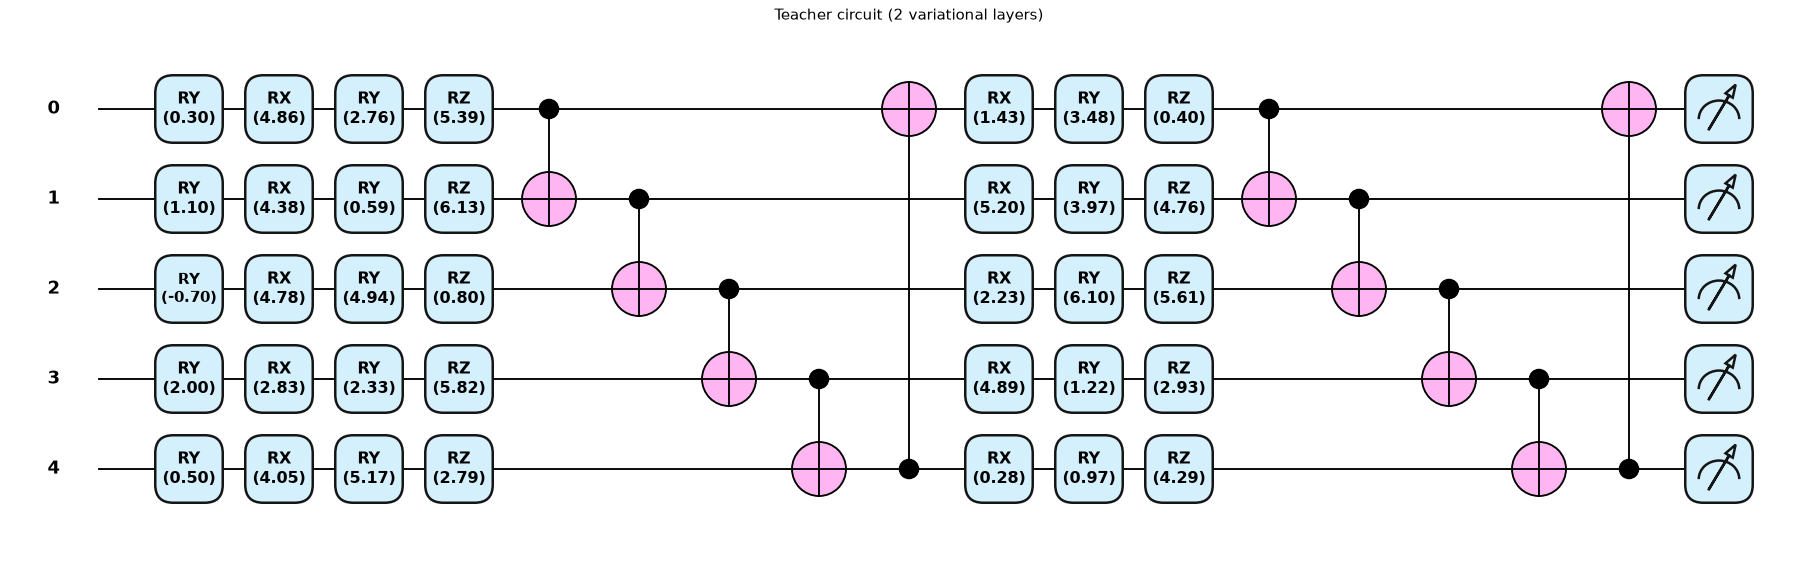

Teacher circuit (2 variational layers): qubits = 5, depth = 17, gates = 45, trainable circuit parameters = 30 (+ 5 encoding angles that come from the trainable classical projection)


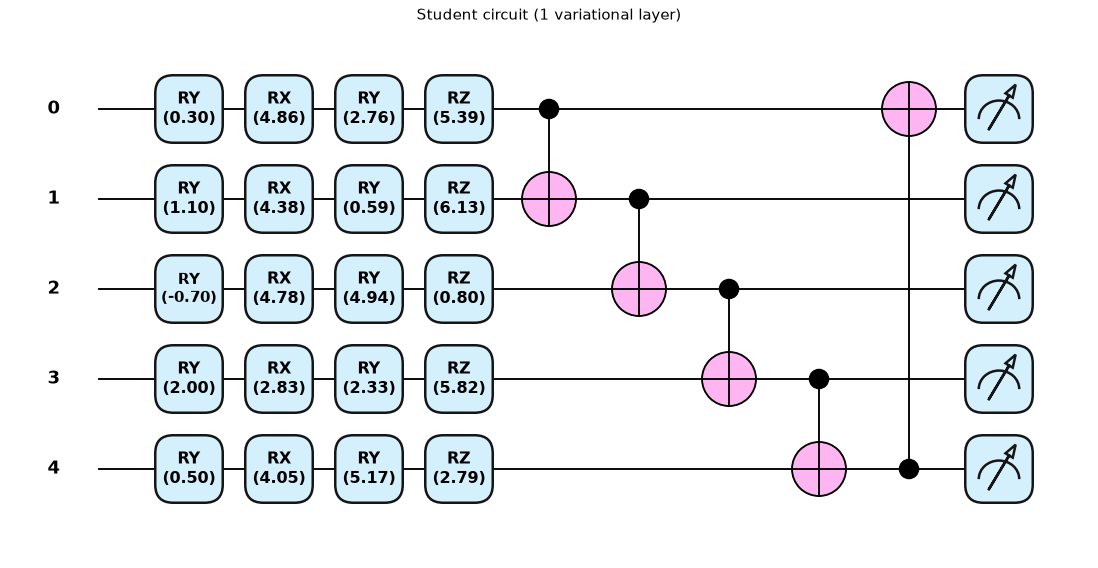

Student circuit (1 variational layer): qubits = 5, depth = 9, gates = 25, trainable circuit parameters = 15 (+ 5 encoding angles that come from the trainable classical projection)


In [13]:
# 5b. Drawings of the circuits that are executed (teacher and student) and their sizes.
for title, layers in [("Teacher circuit (2 variational layers)", L_T), ("Student circuit (1 variational layer)", L_S)]:
    qn = make_qnode(layers)
    z0 = np.array([0.3, 1.1, -0.7, 2.0, 0.5]); th0 = np.random.default_rng(SEED).uniform(0, 2 * np.pi, (layers, N_QUBITS, 3))
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(z0, th0)
    fig.suptitle(title, y=1.02); plt.show()
    res = qml.specs(qn)(z0, th0)["resources"]
    print(f"{title}: qubits = {N_QUBITS}, depth = {res.depth}, gates = {res.num_gates}, trainable circuit parameters = {th0.size} "
          f"(+ {N_QUBITS} encoding angles that come from the trainable classical projection)")

## 4. The hybrid model, the classical twin and the distillation loss

`HybridNet` follows Eq. 24-27 and 12: projection to five angles, circuit (or, for the classical twin, a 5-to-5 linear layer with
`tanh`, which has the same number of parameters as the two-layer circuit, 30), a bidirectional GRU that reads the five numbers as a
sequence, and a dense layer that outputs one logit (sigmoid inside the loss). Local training uses Adam; for the student the loss
is `lambda * BCE(y) + (1 - lambda) * T^2 * BCE(sigmoid(s/T), sigmoid(t/T))`, where `t` are the teacher's logits (Algorithm 1).

In [14]:
class HybridNet(nn.Module):
    """x (D) -> z = pi*tanh(W x + b) (5) -> [VQC (5 qubits) | classical 5->5 + tanh] -> BiGRU(1 -> hid) over the 5 values -> dense logit."""

    def __init__(self, D, quantum=True, layers=2, hid=8):
        super().__init__()
        self.quantum, self.layers, self.hid = quantum, layers, hid
        self.proj = nn.Linear(D, NQ)
        if quantum:
            self.theta = nn.Parameter(torch.rand(layers, NQ, 3) * 2 * math.pi)       # CHOICE: uniform [0, 2pi)
        else:
            self.cl = nn.Linear(NQ, NQ)
        self.rnn = nn.GRU(1, hid, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hid, 1)

    def encode(self, x):
        return math.pi * torch.tanh(self.proj(x))

    def quantum_features(self, x):
        z = self.encode(x)
        if self.quantum:
            return vqc_forward(z, self.theta).to(torch.float32)
        return torch.tanh(self.cl(z))

    def forward(self, x):
        q = self.quantum_features(x)
        _, h = self.rnn(q.unsqueeze(-1))
        h = torch.cat([h[0], h[1]], -1)
        return self.out(h).squeeze(-1)


def get_flat(model):
    return torch.cat([p.detach().reshape(-1) for p in model.parameters()]).double().numpy()


def set_flat(model, vec):
    i = 0
    with torch.no_grad():
        for p in model.parameters():
            n = p.numel()
            p.copy_(torch.as_tensor(vec[i:i + n], dtype=p.dtype).reshape(p.shape))
            i += n


def n_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def predict_logits(model, X, bs=8192):
    model.eval()
    out = [model(torch.as_tensor(X[i:i + bs])) for i in range(0, len(X), bs)]
    return torch.cat(out).numpy()


def local_train(model, X, y, epochs, lr, bs, gen, teacher_logits=None, T=2.0, lam=0.5, log=None):
    """Adam training; with teacher_logits the loss is lam*BCE(y) + (1-lam)*T^2*BCE(sigmoid(s/T), sigmoid(t/T))."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.as_tensor(X), torch.as_tensor(y, dtype=torch.float32)
    tl = None if teacher_logits is None else torch.as_tensor(teacher_logits)
    n = len(Xt)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=gen)
        tot, correct = 0.0, 0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            logit = model(Xt[idx])
            loss = F.binary_cross_entropy_with_logits(logit, yt[idx])
            if tl is not None:
                soft = torch.sigmoid(tl[idx] / T)
                kd = F.binary_cross_entropy_with_logits(logit / T, soft) * T * T
                loss = lam * loss + (1 - lam) * kd
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += float(loss.detach()) * len(idx)
            correct += int(((logit > 0).float() == yt[idx]).sum())
        if log is not None:
            log.append((tot / n, correct / n))

In [15]:
# 6. Sizes of the models (these are what travels / what stays on the device).
for nm, mdl in [("teacher (VQC 2 layers + BiGRU 8)", HybridNet(D, True, L_T, HID_T)), ("student (VQC 1 layer + BiGRU 4)", HybridNet(D, True, L_S, HID_S)),
                ("classical twin teacher", HybridNet(D, False, L_T, HID_T)), ("classical twin student", HybridNet(D, False, L_S, HID_S))]:
    print(f"{nm:36s} parameters = {n_params(mdl):5d}   float32 size = {n_params(mdl)*4/1e3:6.1f} kB")

teacher (VQC 2 layers + BiGRU 8)     parameters =   730   float32 size =    2.9 kB
student (VQC 1 layer + BiGRU 4)      parameters =   347   float32 size =    1.4 kB
classical twin teacher               parameters =   730   float32 size =    2.9 kB
classical twin student               parameters =   362   float32 size =    1.4 kB


## 5. Additively homomorphic encryption of the model parameters

The server must mix `theta_g <- (1 - alpha) theta_g + alpha theta_i` without seeing `theta_i`. With the **Paillier**
cryptosystem, multiplying two ciphertexts adds the hidden numbers and raising a ciphertext to an integer power multiplies the
hidden number by that integer. That is all Eq. 20 needs. The implementation below is pure Python (no library):

* parameters are turned into 24-bit fixed-point integers (with an offset so every number is positive) and **packed**, 15 per
  ciphertext, in 64-bit slots;
* the mixing weights are quantised to multiples of `2^-16` so that `(1 - alpha)` and `alpha` are integers over a common
  denominator;
* the server holds the secret key (as in the paper's Table 7), decrypts only the aggregate and divides out the denominator
  and the offsets.

The paper uses CKKS (approximate arithmetic on real numbers, lattice based). Paillier is exact on integers and not
quantum-resistant; it is chosen here because it can be written in a few dozen lines without a library. A 1024-bit modulus keeps
the demo fast; use at least 2048 bits for anything real. The random numbers come from a seeded generator so that the notebook is
reproducible, which is *not* secure.

In [16]:
# 6a. Paillier cryptosystem with packing and fixed-point coding (pure Python).


def _is_probable_prime(n, rng, rounds=24):
    if n < 4:
        return n in (2, 3)
    if n % 2 == 0:
        return False
    for p in (3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0:
            return n == p
    d, r = n - 1, 0
    while d % 2 == 0:
        d //= 2
        r += 1
    for _ in range(rounds):
        a = rng.randrange(2, n - 2)
        x = pow(a, d, n)
        if x in (1, n - 1):
            continue
        for _ in range(r - 1):
            x = pow(x, 2, n)
            if x == n - 1:
                break
        else:
            return False
    return True


def _random_prime(bits, rng):
    while True:
        c = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
        if _is_probable_prime(c, rng):
            return c


class Paillier:
    """Textbook Paillier (additively homomorphic) with g = n + 1 and slot packing.

    Many fixed-point numbers are packed into one plaintext integer (one `SLOT_BITS`-bit slot each), so one
    ciphertext carries `slots` parameters. Addition of ciphertexts adds the slots; multiplication by a plain
    integer scales every slot. Slots never overflow into each other (checked by assertions)."""

    def __init__(self, key_bits=1024, slot_bits=64, seed=0):
        rng = random.Random(seed)       # CHOICE: seeded generator so the notebook is reproducible (NOT secure)
        while True:
            p = _random_prime(key_bits // 2, rng)
            q = _random_prime(key_bits // 2, rng)
            if p != q and math.gcd(p * q, (p - 1) * (q - 1)) == 1:
                break
        self.p, self.q = p, q
        self.n = p * q
        self.n2 = self.n * self.n
        self.lam = math.lcm(p - 1, q - 1)
        self.slot_bits = slot_bits
        self.slots = (self.n.bit_length() - 2 - 16) // slot_bits   # keep head-room for the scalar multiplication
        self.rng = rng
        self.key_bits = key_bits
        # CRT constants for fast decryption (server holds the secret key)
        self.p2, self.q2 = p * p, q * q
        self.hp = pow((pow(self.n + 1, p - 1, self.p2) - 1) // p, -1, p)
        self.hq = pow((pow(self.n + 1, q - 1, self.q2) - 1) // q, -1, q)
        self.pinv_q = pow(p, -1, q)

    def encrypt_int(self, m, trivial=False):
        if trivial:                       # r = 1: NOT semantically secure; used only for the public global model
            return (1 + m * self.n) % self.n2
        r = self.rng.randrange(2, self.n - 1)
        return ((1 + m * self.n) * pow(r, self.n, self.n2)) % self.n2

    def decrypt_int(self, c):
        mp = (((pow(c, self.p - 1, self.p2) - 1) // self.p) * self.hp) % self.p
        mq = (((pow(c, self.q - 1, self.q2) - 1) // self.q) * self.hq) % self.q
        return mp + self.p * (((mq - mp) * self.pinv_q) % self.q)

    def add(self, c1, c2):
        return (c1 * c2) % self.n2

    def mul_plain(self, c, k):
        return pow(c, k, self.n2)


class FixedPointCodec:
    """float vector <-> list of packed plaintext integers (non-negative slots via an offset)."""

    def __init__(self, he, frac_bits=24, offset_bits=8, weight_bits=16):
        self.he, self.F, self.OFF, self.S = he, frac_bits, 1 << (offset_bits + frac_bits), weight_bits
        self.offset_bits = offset_bits

    def encode(self, v):
        v = np.asarray(v, dtype=np.float64)
        assert np.all(np.abs(v) < (1 << self.offset_bits)), "parameter outside fixed-point range"
        ints = [int(x) + self.OFF for x in np.rint(v * (1 << self.F)).astype(np.int64)]
        sb, k = self.he.slot_bits, self.he.slots
        packed = []
        for i in range(0, len(ints), k):
            m = 0
            for j, x in enumerate(ints[i:i + k]):
                m |= x << (sb * j)
            packed.append(m)
        return packed, len(ints)

    def decode(self, packed, length, total_weight=1):
        """packed plaintexts of sum_i w_i * (v_i + offset); total_weight = sum_i w_i (integer)."""
        sb, k = self.he.slot_bits, self.he.slots
        mask = (1 << sb) - 1
        out = []
        for m in packed:
            for j in range(k):
                out.append(((m >> (sb * j)) & mask))
        out = out[:length]
        arr = np.array([float(x - self.OFF * total_weight) for x in out], dtype=np.float64)
        return arr / ((1 << self.F) * total_weight)

    def encrypt(self, v):
        packed, n = self.encode(v)
        return [self.he.encrypt_int(m) for m in packed], n

    def trivial_encrypt(self, v):
        packed, n = self.encode(v)
        return [self.he.encrypt_int(m, trivial=True) for m in packed]

    def decrypt(self, cts, n, total_weight=1):
        return self.decode([self.he.decrypt_int(c) for c in cts], n, total_weight)

    def fed_async_mix(self, cts_global, cts_client, alpha):
        """Encrypted (1-alpha)*theta_g + alpha*theta_i. alpha is quantised to 2**-S, weights are plain integers."""
        a = int(round(alpha * (1 << self.S)))
        b = (1 << self.S) - a
        he = self.he
        return [he.add(he.mul_plain(cg, b), he.mul_plain(cc, a)) for cg, cc in zip(cts_global, cts_client)], (1 << self.S)

In [17]:
# 7. Key generation and unit tests of the encrypted arithmetic.
t0 = time.time(); he = Paillier(HE_KEY_BITS, 64, seed=SEED); codec = FixedPointCodec(he, HE_FRAC_BITS, 8, HE_WEIGHT_BITS)
print(f"key generation {time.time()-t0:.2f}s | modulus {he.n.bit_length()} bits | {he.slots} parameters per ciphertext")
rs = np.random.default_rng(SEED)
v, w = rs.normal(0, 1.5, 730), rs.normal(0, 1.5, 730)                    # two stand-in parameter vectors (size of the teacher)
t0 = time.time(); cv, n = codec.encrypt(v); t_e = time.time() - t0; cw, _ = codec.encrypt(w)
assert np.abs(codec.decrypt(cv, n) - v).max() < 1e-6, "round trip"
for alpha in (0.6, 0.6 * 3 ** -0.5, 0.05):
    mixed, tw = codec.fed_async_mix(cw, cv, alpha)                         # (1-alpha)*w + alpha*v on ciphertexts
    t0 = time.time(); dec = codec.decrypt(mixed, n, tw); t_d = time.time() - t0
    a_q = round(alpha * 2 ** HE_WEIGHT_BITS) / 2 ** HE_WEIGHT_BITS
    err = np.abs(dec - ((1 - a_q) * w + a_q * v)).max()
    assert err < 1e-6, err
    print(f"alpha = {alpha:.3f}: max |decrypt(mix) - plaintext mix| = {err:.1e}")
print(f"encrypt {len(cv)} ciphertexts ({len(v)} parameters): {t_e:.2f}s | decrypt {t_d:.2f}s | ciphertext {len(cv)*2*he.n.bit_length()/8/1e3:.1f} kB "
      f"vs plaintext float32 {len(v)*4/1e3:.1f} kB (x{len(cv)*2*he.n.bit_length()/8/(len(v)*4):.1f})")
print("staleness rule: s=0 ->", round(ALPHA0, 3), "| s=4 ->", round(ALPHA0 * 5 ** -BETA, 3), "| s=%d ->" % (S_MAX + 1), "discarded (s > S_MAX)")

key generation 0.33s | modulus 1023 bits | 15 parameters per ciphertext


alpha = 0.600: max |decrypt(mix) - plaintext mix| = 2.8e-08


alpha = 0.346: max |decrypt(mix) - plaintext mix| = 2.8e-08


alpha = 0.050: max |decrypt(mix) - plaintext mix| = 2.9e-08
encrypt 49 ciphertexts (730 parameters): 2.04s | decrypt 0.68s | ciphertext 12.5 kB vs plaintext float32 2.9 kB (x4.3)
staleness rule: s=0 -> 0.6 | s=4 -> 0.268 | s=13 -> discarded (s > S_MAX)


## 6. Asynchronous federated training with distillation

`run_fedasync` simulates what the paper's Algorithms 1 and 2 describe:

1. every client starts from the global model it last received and trains the **teacher** locally (Adam, binary cross-entropy);
2. it distils the updated teacher into its private **student** (stays on the device, never uploaded);
3. it encrypts the teacher's parameters and uploads them with the version number it started from;
4. the server computes the staleness `s = t - tau`, the weight `alpha = alpha_0 (1 + s)^(-beta)`, drops the update if `s > S_max`,
   and otherwise mixes it into the global model **on ciphertexts**, then decrypts only the aggregate and sends it back.

A simulated clock with different client speeds decides who arrives first, so updates really are stale. One *round* is
five accepted updates (ten with ten clients). For the classical twin the same code runs without the circuit and without encryption
(encryption was shown above to be lossless, so it only costs time).

In [18]:
# 6b. Asynchronous federated training with encrypted aggregation and local distillation.

def partition_iid(strata, K, seed):
    """Stratified IID split of row indices into K clients (every client keeps the class mix)."""
    rng = np.random.default_rng(seed)
    parts = [[] for _ in range(K)]
    for s in np.unique(strata):
        idx = rng.permutation(np.where(strata == s)[0])
        for k, chunk in enumerate(np.array_split(idx, K)):
            parts[k].extend(chunk.tolist())
    return [np.array(sorted(p)) for p in parts]


def staleness_alpha(s):
    """Eq. (19): alpha_i = alpha_0 (1 + s_i)^(-beta)."""
    return ALPHA0 * (1.0 + s) ** (-BETA)


def metrics_from_logits(y, logit):
    p = 1.0 / (1.0 + np.exp(-logit))
    yhat = (logit > 0).astype(int)
    return dict(acc=100 * accuracy_score(y, yhat), prec=100 * precision_score(y, yhat, zero_division=0),
                rec=100 * recall_score(y, yhat, zero_division=0), f1=100 * f1_score(y, yhat, zero_division=0),
                auc=float(roc_auc_score(y, p)), cm=confusion_matrix(y, yhat, labels=[0, 1]))


def run_fedasync(name, Xc, yc, quantum, rounds, seed, use_he, mon=None, verbose=True):
    """Asynchronous federated training (FedAsync, Eq. 18-21) of the teacher, with local knowledge distillation into a
    client-private student. One 'round' = K accepted updates. Simulated client clock decides the arrival order."""
    K, D = len(Xc), Xc[0].shape[1]
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    rng = np.random.default_rng(seed)
    teacher = HybridNet(D, quantum, L_T, HID_T)
    probe = HybridNet(D, quantum, L_T, HID_T)
    students = [HybridNet(D, quantum, L_S, HID_S) for _ in range(K)]
    theta_g = get_flat(teacher)
    speed = rng.lognormal(0.0, 0.2, K)                      # CHOICE: heterogeneous simulated client speeds
    heap, snap, tau = [], {}, {}
    for k in range(K):
        heapq.heappush(heap, (speed[k] * rng.uniform(0.8, 1.2), k))
        snap[k], tau[k] = theta_g.copy(), 0
    version, discarded = 0, 0
    curves = [[] for _ in range(K)]
    scurves = [[] for _ in range(K)]
    last_local = [None] * K
    n_upd = [0] * K
    hist, round_acc = [], []
    t_local = t_kd = t_enc = t_agg = t_dec = 0.0
    he_err = 0.0
    n_ct = 0
    wall = time.time()
    for u in range(rounds * K):
        now, k = heapq.heappop(heap)
        # --- client k trains from the (possibly outdated) global model it started with ----------------------
        t0 = time.time()
        set_flat(teacher, snap[k])
        local_train(teacher, Xc[k], yc[k], E_TEACHER, LR, BATCH, gen, log=curves[k])
        t_local += time.time() - t0
        flat_i = get_flat(teacher)
        last_local[k] = flat_i.copy()
        n_upd[k] += 1
        # --- local knowledge distillation into the lightweight student (stays on the device) -----------------
        t0 = time.time()
        tl = predict_logits(teacher, Xc[k])
        local_train(students[k], Xc[k], yc[k], E_STUDENT, LR, BATCH, gen, teacher_logits=tl, T=KD_T, lam=KD_LAMBDA,
                    log=scurves[k])
        t_kd += time.time() - t0
        # --- server: staleness-aware mixing ------------------------------------------------------------------
        s = version - tau[k]
        alpha = staleness_alpha(s)
        a_q = round(alpha * (1 << HE_WEIGHT_BITS)) / (1 << HE_WEIGHT_BITS)
        if s > S_MAX:
            discarded += 1
            hist.append((u, k, s, alpha, "discarded"))
        else:
            plain = (1 - a_q) * theta_g + a_q * flat_i
            if use_he:
                t0 = time.time(); cts_i, n = codec.encrypt(flat_i); t_enc += time.time() - t0
                t0 = time.time()
                cts_g = codec.trivial_encrypt(theta_g)
                mixed, tw = codec.fed_async_mix(cts_g, cts_i, alpha)
                t_agg += time.time() - t0
                t0 = time.time(); new = codec.decrypt(mixed, n, tw); t_dec += time.time() - t0
                he_err = max(he_err, float(np.abs(new - plain).max()))
                n_ct = len(cts_i)
                theta_g = new
            else:
                theta_g = plain
            version += 1
            hist.append((u, k, s, alpha, "accepted"))
        # --- the client receives the new global model and starts the next local round --------------------------
        snap[k], tau[k] = theta_g.copy(), version
        heapq.heappush(heap, (now + speed[k] * rng.uniform(0.8, 1.2), k))
        if (u + 1) % K == 0 and mon is not None:
            set_flat(probe, theta_g)
            lg = predict_logits(probe, mon[0])
            round_acc.append(100 * float(((lg > 0).astype(int) == mon[1]).mean()))
            if verbose:
                print(f"  [{name}] round {(u + 1) // K}/{rounds}: monitor-train acc {round_acc[-1]:.2f}%  "
                      f"(elapsed {time.time() - wall:.0f}s)")
    set_flat(teacher, theta_g)
    last_local = [f if f is not None else theta_g.copy() for f in last_local]   # a client that never arrived keeps the global model
    return dict(n_upd=n_upd, name=name, teacher=teacher, theta_g=theta_g, students=students, last_local=last_local,
                curves=curves, scurves=scurves, hist=hist, round_acc=round_acc, discarded=discarded,
                times=dict(local=t_local, kd=t_kd, enc=t_enc, agg=t_agg, dec=t_dec, wall=time.time() - wall),
                he_err=he_err, n_ct=n_ct, K=K, rounds=rounds)

In [19]:
# 8. Test the full loop on a tiny problem before the real runs (fast sanity check of the mechanism, including a discarded update).
_Xc = [Xtr[i::3][:300] for i in range(3)]; _yc = [ytr[i::3][:300] for i in range(3)]
_E = (E_TEACHER, E_STUDENT); _S = S_MAX
E_TEACHER = E_STUDENT = 1; S_MAX = 1                       # S_MAX = 1 forces some stale updates to be discarded
_r = run_fedasync("sanity", _Xc, _yc, True, 2, SEED, True, verbose=False)
E_TEACHER, E_STUDENT = _E; S_MAX = _S
print("updates:", [(h[1], h[2], round(h[3], 3), h[4]) for h in _r["hist"]])
print("discarded:", _r["discarded"], "| max |encrypted aggregate - plaintext aggregate| =", f"{_r['he_err']:.1e}")
assert _r["he_err"] < 1e-6 and _r["discarded"] >= 1

updates: [(1, 0, 0.6, 'accepted'), (0, 1, 0.424, 'accepted'), (2, 2, 0.346, 'discarded'), (1, 1, 0.424, 'accepted'), (0, 1, 0.424, 'accepted'), (2, 2, 0.346, 'discarded')]
discarded: 2 | max |encrypted aggregate - plaintext aggregate| = 3.0e-08


## 7. Training the proposed model (QLFL) with 5 and 10 clients

The monitor accuracy printed after each round is computed on a 3,000-row sample of the **training** split only; the test set is
touched once, at the end, to report results. Training curves (loss and accuracy per local epoch, as in the paper's Figures 4 and 5)
are training metrics, not test metrics.

In [20]:
# 9. Run QLFL (quantum teacher + quantum student, encrypted FedAsync) for every seed, 5 clients.
mon_idx = np.random.default_rng(SEED).choice(len(Xtr), size=min(3000, len(Xtr)), replace=False)
MON = (Xtr[mon_idx], ytr[mon_idx])
runs_q5, runs_c5 = {}, {}
for sd in SEEDS:
    parts = partition_iid(ctr, K_CLIENTS, sd)
    Xc = [Xtr[p] for p in parts]; yc = [ytr[p] for p in parts]
    print(f"--- seed {sd}: QLFL, {K_CLIENTS} clients of ~{len(parts[0])} records each ---")
    runs_q5[sd] = run_fedasync(f"QLFL-5-s{sd}", Xc, yc, True, ROUNDS, sd, True, mon=MON)
    r = runs_q5[sd]
    print(f"    done in {r['times']['wall']:.0f}s | max |encrypted - plaintext aggregate| = {r['he_err']:.1e} | discarded = {r['discarded']} | updates per client = {r['n_upd']}")

--- seed 42: QLFL, 5 clients of ~26418 records each ---


  [QLFL-5-s42] round 1/10: monitor-train acc 99.67%  (elapsed 54s)


  [QLFL-5-s42] round 2/10: monitor-train acc 99.97%  (elapsed 102s)


  [QLFL-5-s42] round 3/10: monitor-train acc 99.97%  (elapsed 150s)


  [QLFL-5-s42] round 4/10: monitor-train acc 99.67%  (elapsed 197s)


...

  [QLFL-5-s44] round 6/10: monitor-train acc 100.00%  (elapsed 294s)


  [QLFL-5-s44] round 7/10: monitor-train acc 100.00%  (elapsed 326s)


  [QLFL-5-s44] round 8/10: monitor-train acc 100.00%  (elapsed 357s)


  [QLFL-5-s44] round 9/10: monitor-train acc 100.00%  (elapsed 380s)


  [QLFL-5-s44] round 10/10: monitor-train acc 100.00%  (elapsed 411s)
    done in 411s | max |encrypted - plaintext aggregate| = 3.0e-08 | discarded = 0 | updates per client = [9, 11, 11, 9, 10]


In [21]:
# 10. Run QLFL with 10 clients (first seed only), as in Fig. 4b-7b.
sd = SEEDS[0]
parts10 = partition_iid(ctr, K_CLIENTS_LARGE, sd)
print(f"--- seed {sd}: QLFL, {K_CLIENTS_LARGE} clients of ~{len(parts10[0])} records each ---")
run_q10 = run_fedasync(f"QLFL-10-s{sd}", [Xtr[p] for p in parts10], [ytr[p] for p in parts10], True, ROUNDS_LARGE, sd, True, mon=MON)
print(f"    done in {run_q10['times']['wall']:.0f}s | max encrypted/plaintext difference {run_q10['he_err']:.1e} | discarded {run_q10['discarded']}")

--- seed 42: QLFL, 10 clients of ~13209 records each ---


  [QLFL-10-s42] round 1/10: monitor-train acc 99.03%  (elapsed 39s)


  [QLFL-10-s42] round 2/10: monitor-train acc 99.90%  (elapsed 74s)


  [QLFL-10-s42] round 3/10: monitor-train acc 99.67%  (elapsed 107s)


  [QLFL-10-s42] round 4/10: monitor-train acc 99.97%  (elapsed 136s)


...

  [QLFL-10-s42] round 6/10: monitor-train acc 99.67%  (elapsed 192s)


  [QLFL-10-s42] round 7/10: monitor-train acc 99.67%  (elapsed 218s)


  [QLFL-10-s42] round 8/10: monitor-train acc 100.00%  (elapsed 252s)


  [QLFL-10-s42] round 9/10: monitor-train acc 100.00%  (elapsed 282s)


  [QLFL-10-s42] round 10/10: monitor-train acc 100.00%  (elapsed 310s)
    done in 310s | max encrypted/plaintext difference 3.0e-08 | discarded 5


In [22]:
# 11. Classical twin of the whole pipeline (same FedAsync schedule, same distillation, 5->5 tanh layer instead of the circuit).
for sd in SEEDS:
    parts = partition_iid(ctr, K_CLIENTS, sd)
    print(f"--- seed {sd}: classical twin, {K_CLIENTS} clients ---")
    runs_c5[sd] = run_fedasync(f"CFL-5-s{sd}", [Xtr[p] for p in parts], [ytr[p] for p in parts], False, ROUNDS, sd, False, mon=MON)
    print(f"    done in {runs_c5[sd]['times']['wall']:.0f}s")

--- seed 42: classical twin, 5 clients ---

  [CFL-5-s42] round 1/10: monitor-train acc 99.67%  (elapsed 6s)


  [CFL-5-s42] round 2/10: monitor-train acc 99.97%  (elapsed 12s)


  [CFL-5-s42] round 3/10: monitor-train acc 99.67%  (elapsed 19s)


  [CFL-5-s42] round 4/10: monitor-train acc 99.97%  (elapsed 27s)


...

  [CFL-5-s44] round 6/10: monitor-train acc 99.97%  (elapsed 63s)


  [CFL-5-s44] round 7/10: monitor-train acc 99.97%  (elapsed 76s)


  [CFL-5-s44] round 8/10: monitor-train acc 99.97%  (elapsed 90s)


  [CFL-5-s44] round 9/10: monitor-train acc 99.97%  (elapsed 102s)


  [CFL-5-s44] round 10/10: monitor-train acc 99.97%  (elapsed 112s)
    done in 112s


In [23]:
# 12. Federated random forest (each client grows a forest on its own share; probabilities are averaged) and a centralised forest.
def rf_fed(parts, sd):
    forests = [RandomForestClassifier(n_estimators=40, max_depth=10, random_state=sd, n_jobs=1).fit(Xtr[p], ytr[p]) for p in parts]
    return forests
def rf_logit(forests, X):
    p = np.mean([f.predict_proba(X)[:, 1] for f in forests], axis=0).clip(1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
rf_res, rf_cent_res = {}, {}
for sd in SEEDS:
    t0 = time.time(); fs = rf_fed(partition_iid(ctr, K_CLIENTS, sd), sd); lg = rf_logit(fs, Xte)
    rf_res[sd] = dict(metrics_from_logits(yte, lg), t=time.time() - t0)
    t0 = time.time(); fc = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=sd, n_jobs=1).fit(Xtr, ytr)
    rf_cent_res[sd] = dict(metrics_from_logits(yte, rf_logit([fc], Xte)), t=time.time() - t0)
print("federated RF accuracy:", {s: round(r['acc'], 2) for s, r in rf_res.items()}, "| centralised RF accuracy:", {s: round(r['acc'], 2) for s, r in rf_cent_res.items()})

federated RF accuracy: {42: 100.0, 43: 100.0, 44: 100.0} | centralised RF accuracy: {42: 100.0, 43: 100.0, 44: 100.0}


## 8. Test-set results

The global teacher (the model that the federated protocol produces) is the model whose accuracy the abstract reports. "Client
local model" is the last locally trained teacher of a client before its final upload, and "student" is that client's private
distilled model; both are scored on the same held-out test set, the way the paper's per-client Figure 3 and Table 6 appear to be.

In [24]:
# 13. Evaluate everything on the isolated test set (single pass).
def eval_model(m): return metrics_from_logits(yte, predict_logits(m, Xte))
def eval_flat(quantum, flat, layers, hid):
    m = HybridNet(D, quantum, layers, hid); set_flat(m, flat); return eval_model(m)
RES = {}   # (family, seed) -> dict of metrics
for sd in SEEDS:
    q, c = runs_q5[sd], runs_c5[sd]
    RES[("QLFL global teacher", sd)] = eval_model(q["teacher"])
    RES[("QLFL client-1 local teacher", sd)] = eval_flat(True, q["last_local"][0], L_T, HID_T)
    qc = [eval_flat(True, f, L_T, HID_T) for f, n in zip(q["last_local"], q["n_upd"]) if n > 0]
    RES[("QLFL client local teachers (mean)", sd)] = {k: float(np.mean([x[k] for x in qc])) for k in ("acc", "prec", "rec", "f1", "auc")}
    qs = [eval_model(s) for s, n in zip(q["students"], q["n_upd"]) if n > 0]
    RES[("QLFL students (mean)", sd)] = {k: float(np.mean([x[k] for x in qs])) for k in ("acc", "prec", "rec", "f1", "auc")}
    RES[("Classical twin global teacher", sd)] = eval_model(c["teacher"])
    cs = [eval_model(s) for s, n in zip(c["students"], c["n_upd"]) if n > 0]
    RES[("Classical twin students (mean)", sd)] = {k: float(np.mean([x[k] for x in cs])) for k in ("acc", "prec", "rec", "f1", "auc")}
    RES[("Federated random forest", sd)] = rf_res[sd]
    RES[("Centralised random forest", sd)] = rf_cent_res[sd]
    RES[("_qc_all", sd)] = qc
RES[("QLFL global teacher, 10 clients", SEEDS[0])] = eval_model(run_q10["teacher"])
qc10 = [eval_flat(True, f, L_T, HID_T) for f, n in zip(run_q10["last_local"], run_q10["n_upd"]) if n > 0]
fam = []
for f in dict.fromkeys(k[0] for k in RES if not k[0].startswith("_")):
    rows = [RES[(f, s)] for s in SEEDS if (f, s) in RES]
    row = {"model": f, "seeds": len(rows)}
    for k, lab in [("acc", "accuracy %"), ("prec", "precision %"), ("rec", "recall %"), ("f1", "F1 %"), ("auc", "ROC-AUC")]:
        vals = [r[k] for r in rows]
        row[lab] = f"{np.mean(vals):.3f} +- {np.std(vals):.3f}" if len(vals) > 1 else f"{vals[0]:.3f}"
    fam.append(row)
table = pd.DataFrame(fam)
print(table.to_string(index=False))

                            model  seeds       accuracy %      precision %         recall %             F1 %        ROC-AUC
              QLFL global teacher      3  99.933 +- 0.000  99.842 +- 0.000 100.000 +- 0.000  99.921 +- 0.000 1.000 +- 0.000
      QLFL client-1 local teacher      3  99.933 +- 0.000  99.842 +- 0.000 100.000 +- 0.000  99.921 +- 0.000 1.000 +- 0.000
QLFL client local teachers (mean)      3  99.932 +- 0.000  99.841 +- 0.001 100.000 +- 0.000  99.920 +- 0.000 1.000 +- 0.000
             QLFL students (mean)      3  99.918 +- 0.009  99.840 +- 0.000  99.966 +- 0.022  99.903 +- 0.011 1.000 +- 0.000
    Classical twin global teacher      3  99.888 +- 0.002  99.839 +- 0.004  99.896 +- 0.000  99.868 +- 0.002 1.000 +- 0.000
   Classical twin students (mean)      3  99.833 +- 0.035  99.797 +- 0.064  99.809 +- 0.123  99.803 +- 0.041 0.999 +- 0.001
          Federated random forest      3 100.000 +- 0.000 100.000 +- 0.000 100.000 +- 0.000 100.000 +- 0.000 1.000 +- 0.000
        

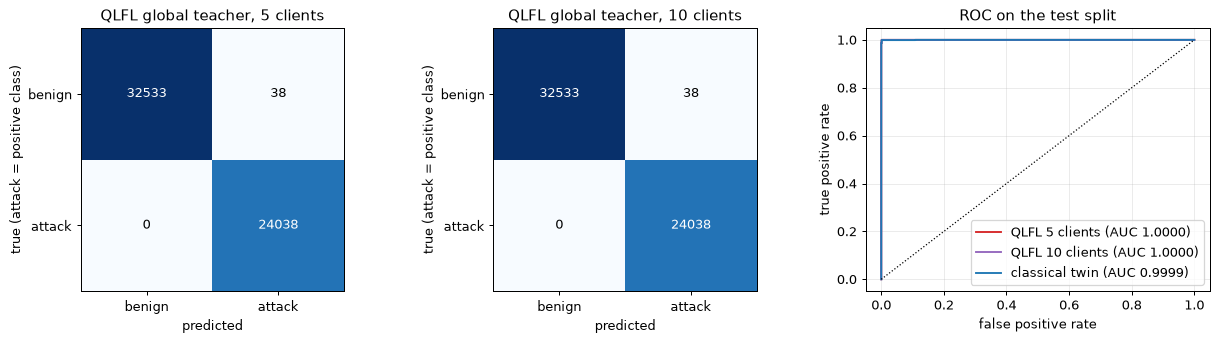

per real traffic class, share classified as attack by the global teacher (5 clients):
  Attack                 n= 24038  predicted attack: 100.00 %   (recall)
  patientMonitoring      n= 23043  predicted attack:   0.10 %   (false-positive rate)
  environmentMonitoring  n=  9528  predicted attack:   0.15 %   (false-positive rate)


In [25]:
# 14. Confusion matrices and ROC curves of the global teacher, 5 and 10 clients (Fig. 6 and 7), and per-real-class recall.
sd = SEEDS[0]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for a, (nm, mdl) in zip(ax[:2], [("5 clients", runs_q5[sd]["teacher"]), ("10 clients", run_q10["teacher"])]):
    lg = predict_logits(mdl, Xte); cm = metrics_from_logits(yte, lg)["cm"]
    a.imshow(cm, cmap="Blues"); a.set_title(f"QLFL global teacher, {nm}"); a.grid(False)
    a.set_xticks([0, 1]); a.set_xticklabels(["benign", "attack"]); a.set_yticks([0, 1]); a.set_yticklabels(["benign", "attack"])
    a.set_xlabel("predicted"); a.set_ylabel("true (attack = positive class)")
    for i in range(2):
        for j in range(2):
            a.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
from sklearn.metrics import roc_curve
for nm, mdl, col in [("QLFL 5 clients", runs_q5[sd]["teacher"], "#d62728"), ("QLFL 10 clients", run_q10["teacher"], "#9467bd"),
                     ("classical twin", runs_c5[sd]["teacher"], "#1f77b4")]:
    lg = predict_logits(mdl, Xte); fpr, tpr, _ = roc_curve(yte, lg)
    ax[2].plot(fpr, tpr, color=col, label=f"{nm} (AUC {metrics_from_logits(yte, lg)['auc']:.4f})")
ax[2].plot([0, 1], [0, 1], "k:", lw=1); ax[2].set_xlabel("false positive rate"); ax[2].set_ylabel("true positive rate"); ax[2].set_title("ROC on the test split"); ax[2].legend(loc="lower right")
plt.tight_layout(); plt.show()
pred = (predict_logits(runs_q5[sd]["teacher"], Xte) > 0).astype(int)
print("per real traffic class, share classified as attack by the global teacher (5 clients):")
for c in CLASS_ORDER:
    m = cte == c
    print(f"  {c:22s} n={int(m.sum()):6d}  predicted attack: {100*pred[m].mean():6.2f} %   ({'recall' if c=='Attack' else 'false-positive rate'})")

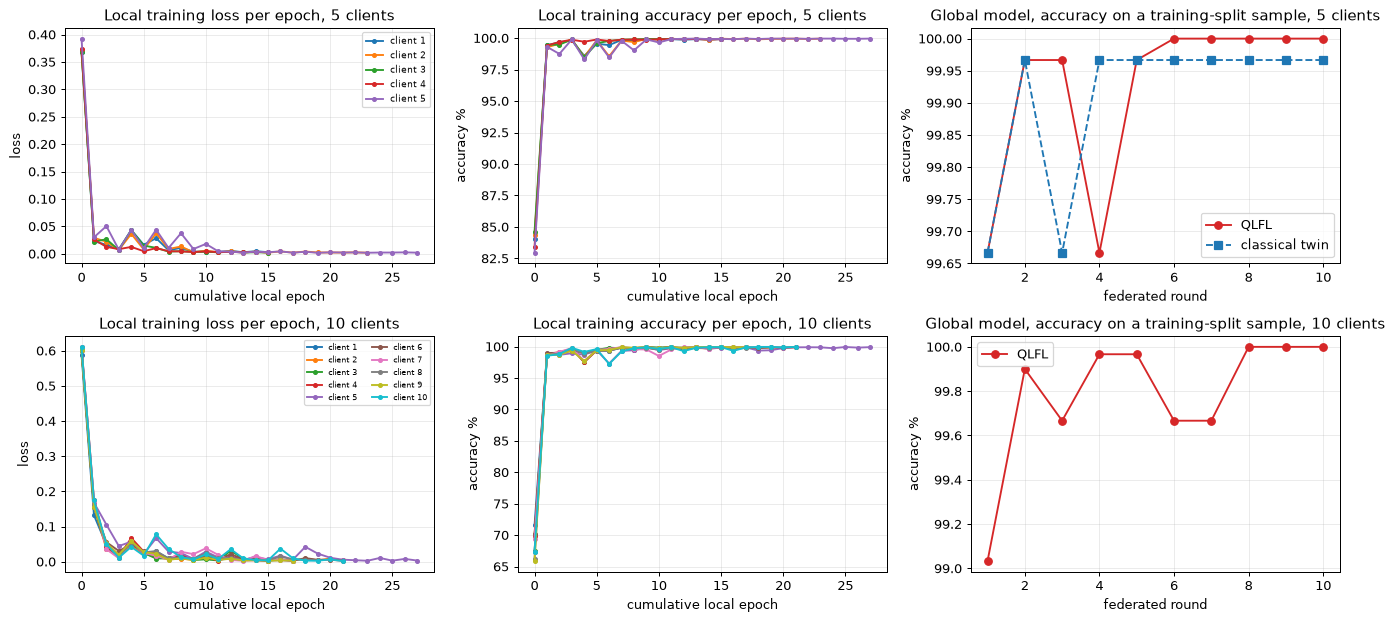

In [26]:
# 15. Per-client training curves (Fig. 4 and 5: loss and accuracy per local epoch; TRAINING metrics) and round-wise monitor accuracy.
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for row, (nm, run) in enumerate([("5 clients", runs_q5[SEEDS[0]]), ("10 clients", run_q10)]):
    for k, cv in enumerate(run["curves"]):
        ax[row, 0].plot([c[0] for c in cv], marker="o", ms=3, label=f"client {k+1}")
        ax[row, 1].plot([100 * c[1] for c in cv], marker="o", ms=3, label=f"client {k+1}")
    ax[row, 0].set_title(f"Local training loss per epoch, {nm}"); ax[row, 0].set_xlabel("cumulative local epoch"); ax[row, 0].set_ylabel("loss")
    ax[row, 1].set_title(f"Local training accuracy per epoch, {nm}"); ax[row, 1].set_xlabel("cumulative local epoch"); ax[row, 1].set_ylabel("accuracy %")
    ax[row, 2].plot(range(1, len(run["round_acc"]) + 1), run["round_acc"], "o-", color="#d62728", label="QLFL")
    if row == 0:
        ax[row, 2].plot(range(1, len(runs_c5[SEEDS[0]]["round_acc"]) + 1), runs_c5[SEEDS[0]]["round_acc"], "s--", color="#1f77b4", label="classical twin")
    ax[row, 2].set_title(f"Global model, accuracy on a training-split sample, {nm}"); ax[row, 2].set_xlabel("federated round"); ax[row, 2].set_ylabel("accuracy %"); ax[row, 2].legend()
ax[0, 0].legend(fontsize=7); ax[1, 0].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

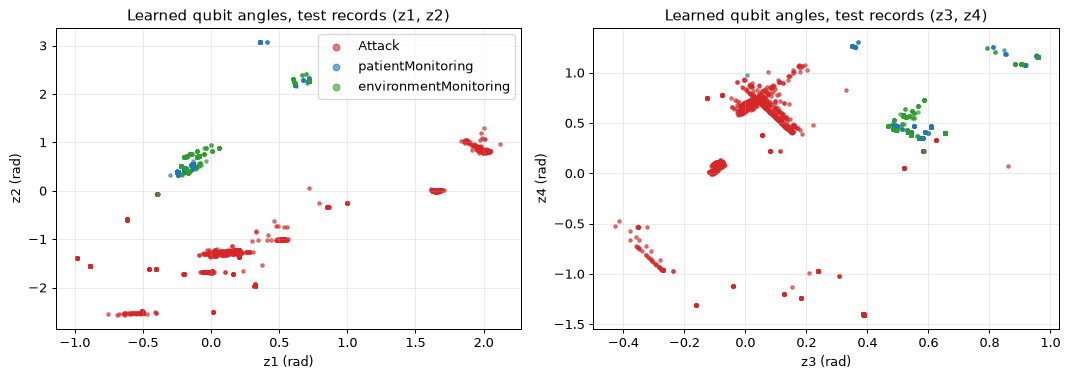

In [27]:
# 16. The angles the trained model actually feeds to the circuit (learned projection z = pi*tanh(Wx+b)), real test records
#     coloured by ground-truth class. This is the analogue of the "angle" map of section 2 for the trained QLFL model.
mdl = runs_q5[SEEDS[0]]["teacher"]
with torch.no_grad():
    Z = mdl.encode(torch.as_tensor(Xte)).numpy()
pk = np.random.default_rng(SEED).choice(len(Xte), size=min(N_PLOT, len(Xte)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for c in CLASS_ORDER:
    m = cte[pk] == c
    ax[0].scatter(Z[pk][m, 0], Z[pk][m, 1], s=7, alpha=0.6, c=CLASS_COL[c], label=c)
    ax[1].scatter(Z[pk][m, 2], Z[pk][m, 3], s=7, alpha=0.6, c=CLASS_COL[c], label=c)
ax[0].set_xlabel("z1 (rad)"); ax[0].set_ylabel("z2 (rad)"); ax[1].set_xlabel("z3 (rad)"); ax[1].set_ylabel("z4 (rad)")
ax[0].set_title("Learned qubit angles, test records (z1, z2)"); ax[1].set_title("Learned qubit angles, test records (z3, z4)"); ax[0].legend(markerscale=2)
plt.tight_layout(); plt.show()

## 9. Cost: encryption, model size and latency (Table 7 and 8 analogues)

These numbers come from a shared CPU and a Python implementation, not from the paper's A100 server and PySEAL, so they are
reported but cannot be matched against the paper's values.

In [28]:
# 17. Costs measured in this run.
r = runs_q5[SEEDS[0]]; T = r["times"]; U = ROUNDS * K_CLIENTS
tm = HybridNet(D, True, L_T, HID_T); sm = HybridNet(D, True, L_S, HID_S)
def latency(model, n=300):
    model.eval(); x = torch.as_tensor(Xte[:n]); t0 = time.time()
    with torch.no_grad():
        for i in range(n):
            model(x[i:i + 1])
    return 1000 * (time.time() - t0) / n
lat_t, lat_s = latency(tm), latency(sm)
red = 100 * (1 - n_params(sm) / n_params(tm))
n_ct = r["n_ct"]; ct_bytes = n_ct * 2 * he.n.bit_length() // 8
cost = pd.DataFrame([
    ("local training time per accepted update (s, teacher)", T["local"] / U),
    ("distillation time per update (s, student)", T["kd"] / U),
    ("encryption time per update (s)", T["enc"] / U),
    ("encrypted aggregation time per update (s)", T["agg"] / U),
    ("decryption time per update (s)", T["dec"] / U),
    ("wall-clock for the whole run (s)", T["wall"]),
    ("teacher parameters / float32 size (kB)", f"{n_params(tm)} / {n_params(tm)*4/1e3:.1f}"),
    ("student parameters / float32 size (kB)", f"{n_params(sm)} / {n_params(sm)*4/1e3:.1f}"),
    ("student smaller than teacher by (%)", red),
    ("ciphertexts per update / bytes", f"{n_ct} / {ct_bytes}"),
    ("encrypted vs plaintext update size (x)", ct_bytes / (n_params(tm) * 4)),
    ("single-record latency, teacher (ms)", lat_t),
    ("single-record latency, student (ms)", lat_s),
], columns=["measure", "value"])
print(cost.to_string(index=False))

                                             measure       value
local training time per accepted update (s, teacher)    4.921927
           distillation time per update (s, student)    2.515048
                      encryption time per update (s)    1.566554
           encrypted aggregation time per update (s)    0.060142
                      decryption time per update (s)    0.513111
                    wall-clock for the whole run (s)  479.432469
              teacher parameters / float32 size (kB)   730 / 2.9
              student parameters / float32 size (kB)   347 / 1.4
                 student smaller than teacher by (%)   52.465753
                      ciphertexts per update / bytes  49 / 12531
              encrypted vs plaintext update size (x)    4.291438
                 single-record latency, teacher (ms)    2.742926
                 single-record latency, student (ms)    1.875847


## 10. Side by side with the paper

Each claim gets a verdict. *Reproduced* means within 2 points (2 percentage points for accuracy, precision, recall, F1;
0.02 for AUC) of the paper's figure; *exceeded* means more than that above; *not reached* more than that below; *cannot be
checked* means the paper's number depends on something this notebook cannot reproduce (a different dataset version, an
unspecified architecture, other hardware or software).

In [29]:
# 18. Claim-by-claim verdicts.
def verdict(paper, ours, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})")
def mean_of(fam, key): return float(np.mean([RES[(fam, s)][key] for s in SEEDS]))
g5 = mean_of("QLFL global teacher", "acc")
c1 = {k: float(np.mean([RES[("QLFL client-1 local teacher", s)][k] for s in SEEDS])) for k in ("acc", "prec", "rec", "f1", "auc")}
auc_max = float(np.mean([max(x["auc"] for x in RES[("_qc_all", s)]) for s in SEEDS]))
g10 = RES[("QLFL global teacher, 10 clients", SEEDS[0])]["acc"]
stu_acc = mean_of("QLFL students (mean)", "acc")
n_ben_pub = int((y_all == 0).sum()); n_att_pub = int((y_all == 1).sum())
rows = [
    ("Accuracy 98.90 % (abstract, conclusion)", "98.90", f"{g5:.2f} (global teacher, 5 clients)", verdict(98.90, g5)),
    ("Accuracy 98.37 % (Fig. 3, Table 9, client 1)", "98.37", f"{c1['acc']:.2f} (client-1 local model)", verdict(98.37, c1["acc"])),
    ("Precision 99.40 % (Fig. 3, client 1)", "99.40", f"{c1['prec']:.2f}", verdict(99.40, c1["prec"])),
    ("Recall 99.01 % (Fig. 3, client 1)", "99.01", f"{c1['rec']:.2f}", verdict(99.01, c1["rec"])),
    ("F1 99.20 % (Fig. 3, client 1)", "99.20", f"{c1['f1']:.2f}", verdict(99.20, c1["f1"])),
    ("Highest ROC-AUC 0.9990 (Fig. 7)", "0.9990", f"{auc_max:.4f} (best client)", verdict(0.9990, auc_max, 0.02)),
    ("Same level with 10 clients as with 5 (Fig. 4-7)", "no number", f"10 clients {g10:.2f} vs 5 clients {g5:.2f}", "reproduced" if abs(g10 - g5) <= 2 else "not reached"),
    ("Lightweight student keeps the quality (Algorithm 1)", "not quantified", f"students {stu_acc:.2f} vs global teacher {g5:.2f}", "reproduced" if abs(stu_acc - g5) <= 2 else ("exceeded (+%.2f)" % (stu_acc - g5) if stu_acc > g5 else "not reached (%.2f)" % (stu_acc - g5))),
    ("Encrypted aggregation = plaintext average (Eq. 20-21)", "implied", f"max difference {max(runs_q5[s]['he_err'] for s in SEEDS):.1e}", "reproduced" if max(runs_q5[s]['he_err'] for s in SEEDS) < 1e-6 else "not reached"),
    ("Table 5 counts (benign 161,043 / attack 80,126)", "161,043 / 80,126", f"{n_ben_pub:,} / {n_att_pub:,} in the public files", "attack count reproduced; benign count not reproduced"),
    ("Table 6 per-class results (4 attack sub-types)", "5 classes", "public data has one 'Attack' class", "cannot be checked"),
    ("Student 45.6 % smaller (Table 8)", "45.6 %", f"{red:.1f} % (different baseline: our teacher)", "cannot be checked"),
    ("Detection latency 47 ms, round 2.35 s, CKKS 214 ms (Tables 7, 8)", "see paper", f"student {lat_s:.2f} ms, round {T['wall']/ROUNDS:.1f} s, Paillier enc {T['enc']/U:.1f} s", "cannot be checked"),
]
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 80, "display.width", 200)
print(cmp_df.to_string(index=False))
v = cmp_df["verdict"].map(lambda s: "reproduced" if s.startswith("reproduced") else ("cannot be checked" if s.startswith("cannot") else ("exceeded" if s.startswith("exceeded") else ("not reached" if s.startswith("not reached") else "partly reproduced"))))
print("\nverdict counts:", v.value_counts().to_dict())
q_gap = mean_of("QLFL global teacher", "acc") - mean_of("Classical twin global teacher", "acc")
print(f"\nQLFL minus classical twin (global teacher accuracy): {q_gap:+.3f} points; QLFL minus centralised random forest: {g5 - mean_of('Centralised random forest', 'acc'):+.3f}")
consist = 100 * (1 - 0.3322 * (1 - 0.9901) - 0.3322 * 0.9901 * (1 / 0.9940 - 1))   # accuracy implied by P=99.40, R=99.01 and 33.2 % attacks
print(f"internal consistency of the paper: precision 99.40 % and recall 99.01 % with the Table 5 attack share (33.2 %) imply an accuracy of about {consist:.2f} %, not 98.37 %")

                                                           claim            paper                                     this notebook                                              verdict
                         Accuracy 98.90 % (abstract, conclusion)            98.90                 99.93 (global teacher, 5 clients)                                           reproduced
                    Accuracy 98.37 % (Fig. 3, Table 9, client 1)            98.37                      99.93 (client-1 local model)                                           reproduced
                            Precision 99.40 % (Fig. 3, client 1)            99.40                                             99.84                                           reproduced
                               Recall 99.01 % (Fig. 3, client 1)            99.01                                            100.00                                           reproduced
                                   F1 99.20 % (Fig. 3, client 1)           

## 11. Reading the paper critically

**What the executed run shows** (`FAST_MODE = False`, 3 seeds, 5 clients; one seed with 10 clients). The global QLFL teacher
reaches 99.93 % accuracy (precision 99.84 %, recall 100 %, ROC-AUC 1.000), the classical twin 99.89 %, the federated and the
centralised random forest 100 %. The numbers of the paper (98.90 % or 98.37 %) are therefore *matched within the 2-point
tolerance and slightly exceeded*, with the 10-client run at the same level and the distilled students 52 % smaller than the
teacher at the same accuracy. The encrypted aggregate equals the plaintext one to 3e-08 in every update. The standard
deviations over seeds are close to zero because the task saturates: the model errors are a few dozen benign records out of
56,609. What the run does **not** show is any advantage of the quantum layer: the difference to the classical twin (0.05
points) is smaller than the gap to the random forest. In the 10-client run five stale updates were discarded by the
`S_MAX = 12` rule, which shows the staleness mechanism at work.

* **The headline accuracy differs inside the paper.** The abstract and conclusion say 98.90 %, Figure 3 and Table 9 say 98.37 %.
  Also, Figure 3's precision 99.40 % and recall 99.01 % cannot both belong to an accuracy of 98.37 % when attacks are one third of
  the records (they would imply about 99.5 %), so the quoted numbers do not come from one confusion matrix.
* **The task is nearly trivial on this data.** A random forest on a handful of TCP/MQTT header fields is essentially perfect
  (the table above). Attack records differ strongly from the ICU sensor traffic in header fields such as TCP window size,
  header length and inter-arrival time. An accuracy near 99 % therefore says little about the *quantum* layer: the classical twin and the forests get
  the same result with no circuit, no encryption and no federation. The paper itself says the results "do not establish
  computational quantum supremacy".
* **Captures leak the label.** Source addresses of attack traffic come from other subnets (table in section 1). With IPs as
  features, any model is perfect for the wrong reason. The paper does not say which 51 columns it used.
* **Label and class mismatch.** Section "Description of dataset" calls the target multi-class and then binary; Table 6 reports
  five classes, but the public files have no attack sub-types, and Table 5's benign counts do not match the public files.
* **Training curves are not test curves.** The paper admits Figures 4 and 5 are training metrics, uses one seed, an IID split
  and no confidence intervals; the same caveats apply here. Duplicated feature rows (about 5 % of the records) can sit on both
  sides of a random split.
* **Compute claims are not checkable.** "200 epochs per round, 10 rounds" of a simulated quantum model in 118 s, 47 ms latency,
  CKKS in 214 ms, are tied to hardware and unreleased code. The method for distillation (Algorithms 1 and 2) is a figure without
  text, so student size and temperature are guesses.
* **Encryption.** The abstract promises additive homomorphic encryption, the body uses CKKS; aggregation of ciphertexts is
  exact enough (checked above), but the server holds the secret key, so it could decrypt a single client update; privacy
  against a curious or compromised server is not provided (the paper's Table 7 states that the server is trusted).

## 12. Exercises

1. Add the IP and port columns back to the feature list and watch every model reach 100 %. Explain why that is not detection.
2. Replace the IID partition by a skewed one (for example one client holds only patient-monitoring benign traffic). Does FedAsync
   with `alpha_0 = 0.6` still converge? Which `beta` helps?
3. Set `S_MAX = 2` and `K_CLIENTS_LARGE = 10`; count the discarded updates and measure the accuracy change.
4. Change the student to `HID_S = 2` and `L_S = 1`, or remove the distillation term (`KD_LAMBDA = 1.0`). How small can the student get
   before the accuracy drops by one point?
5. Increase `HE_KEY_BITS` to 2048 and measure how encryption time grows. Then try `HE_FRAC_BITS = 12`: what is the largest aggregation
   error the printed unit test reports, and does accuracy change?